[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/giulia-open-lab/sionna-rt-course/blob/main/notebooks/03_reference.ipynb)

# Lab 3 reference: Python, NumPy and Sionna RT by example

**What it is for.** In Lab 3 you write short pieces of code. You know what a mean, a percentile or a
least-squares fit is; this notebook shows how to *write* them in Python, from a single line to a call
of the ray tracer. Each example is short, runs on its own and uses other data than the lab (made-up
numbers, or the street canyon of Lab 2): it shows the syntax, not the solution. Each TODO cell of the
lab cites the examples it needs as "ref helpers" and their number: "ref helpers 1.4" is example 4
of Part 1.

**How to use it.** Run the setup cell and the import cell, then any example: read the code and its
output, change a value and run it again. Part 1 covers Python and NumPy, from simple to more complex;
Part 2 the calls of Sionna RT, the ray-tracing (RT) module of the library Sionna
([documentation](https://nvlabs.github.io/sionna/rt/index.html)).

| Example | Content | Used in the lab, exercise |
|---|---|---|
| | **Part 1 - Python and NumPy** | |
| 1.1 | Lists, loops and conditions | 5, 6 |
| 1.2 | Functions: arguments and returned values | all |
| 1.3 | Arrays and statistics: mean, median, percentile, standard deviation | 1, 3 |
| 1.4 | Boolean masks: select values, compute a percentage | 1, 2 |
| 1.5 | 2D arrays: grids, maps, the best option | 1, 6 |
| 1.6 | A loop that fills an array, row by row | 4 |
| 1.7 | Fitting a straight line | 3 |
| | **Part 2 - Sionna RT** | |
| 2.1 | A scene and its height map | 1 |
| 2.2 | Change a scene: frequency, antennas, transmitter, materials | 5 |
| 2.3 | Radio maps | 2 |
| 2.4 | Paths to many receivers and root-mean-square (RMS) delay spread | 4 |
| 2.5 | Several transmitters: best server and transmit power | 6 |

In [1]:
# Setup: install Sionna RT if it is missing (Colab), select the Mitsuba variant, print versions
import importlib.util
import os
import sys
import time

SIONNA_RT_VERSION = "2.2.0"   # version this notebook was written and tested with
FORCE_CPU = False             # True: use the CPU (LLVM) variant even if a GPU is available

if importlib.util.find_spec("sionna") is None:
    if "google.colab" in sys.modules:
        print(f"Installing sionna-rt=={SIONNA_RT_VERSION}. The runtime will restart: "
              "when it has restarted, run this cell again.")
        os.system(f"pip install -q sionna-rt=={SIONNA_RT_VERSION}")
        os.kill(os.getpid(), 5)   # restart the runtime, as in the official Sionna tutorials
    else:
        raise ImportError("sionna-rt is not installed: run 'pip install -r requirements.txt' "
                          "(see the README)")
if "google.colab" in sys.modules:
    import urllib.request   # Colab: download the helpers of the labs from the course repository
    for helpers in ("lab_helpers.py", "lab3_helpers.py"):
        if not os.path.exists(helpers):
            urllib.request.urlretrieve("https://raw.githubusercontent.com/giulia-open-lab/sionna-rt-course/"
                                       f"main/notebooks/{helpers}", helpers)

import mitsuba as mi
if FORCE_CPU:
    mi.set_variant("llvm_ad_mono_polarized")   # must be set before importing sionna.rt
try:
    import sionna.rt   # selects the CUDA variant (NVIDIA's GPU platform) if a GPU is available,
                      # otherwise the LLVM variant (a compiler for the CPU)
except ImportError as err:
    if "LLVM" in str(err):
        raise RuntimeError("No GPU was found and the LLVM library needed by the CPU variant is "
                           "missing. Install it (on Ubuntu, e.g. 'sudo apt install libllvm18') or "
                           "ask the lab administrators; see the README.") from err
    raise

import drjit as dr
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sionna.rt import (ITURadioMaterial, PathSolver, PlanarArray, RadioMapSolver, Receiver,
                       Transmitter, load_scene)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42   # seed passed to every ray-tracing call

device = "GPU (CUDA)" if mi.variant().startswith("cuda") else "CPU (LLVM)"
print(f"Python {sys.version.split()[0]} | sionna-rt {sionna.rt.__version__} | "
      f"Mitsuba {mi.__version__} | Dr.Jit {dr.__version__}")
print(f"NumPy {np.__version__} | matplotlib {matplotlib.__version__}")
print(f"Mitsuba variant: {mi.variant()}  ->  running on {device}")
if sionna.rt.__version__ != SIONNA_RT_VERSION:
    print(f"WARNING: this notebook was tested with sionna-rt {SIONNA_RT_VERSION}")

Python 3.13.16 | sionna-rt 2.2.0 | Mitsuba 3.9.1 | Dr.Jit 1.5.0
NumPy 2.1.3 | matplotlib 3.10.0
Mitsuba variant: cuda_ad_mono_polarized  ->  running on GPU (CUDA)


In [2]:
from lab3_helpers import *   # helpers of Lab 3 (file lab3_helpers.py)

## Part 1 - Python and NumPy

The syntax of the operations of the lab, from simple to more complex, on made-up numbers.

### 1.1 - Lists, loops and conditions

A list holds values in order: `[]` is an empty list, `append` adds a value at the end, `+` joins two
lists, `len` counts the values, `x[0]` is the first and `x[-1]` the last. `for k in range(n):` repeats
the indented lines for k = 0, 1, ..., n-1 (`for _ in range(n):` when k is not needed); `for p in x:`
goes through the values of a list. `if condition:` runs its lines only when the condition holds,
`else:` otherwise; `x is not None` checks that an argument was given. A list comprehension,
`[f(p) for p in x]`, builds a list in one line.

In [3]:
powers = [-71.0, -85.5, -93.2]               # a list of received powers [dBm]
powers.append(-60.4)                         # add a value at the end
print("list:", powers, "| length:", len(powers), "| first:", powers[0], "| last:", powers[-1])
print("[3, 7] + [5] =", [3, 7] + [5])       # + joins two lists into a new one

for k in range(len(powers)):                 # k = 0, 1, 2, 3: the indented lines run once for each k
    if powers[k] >= -90.0:
        print(f"value {k}: {powers[k]} dBm, covered")
    else:
        print(f"value {k}: {powers[k]} dBm, not covered")

covered = []                                 # an empty list, filled in the loop
for p in powers:                             # p takes each value of the list
    if p >= -90.0:
        covered.append(p)
print("covered values:", covered)

margins = [round(p + 90.0, 1) for p in powers]   # list comprehension: one new value per value of powers
print("margins over -90 dBm:", margins)

frequency_ghz = None                         # None: no value given
if frequency_ghz is not None:
    print("change the frequency to", frequency_ghz, "GHz")
else:
    print("no frequency given: nothing to change")

list: [-71.0, -85.5, -93.2, -60.4] | length: 4 | first: -71.0 | last: -60.4
[3, 7] + [5] = [3, 7, 5]
value 0: -71.0 dBm, covered
value 1: -85.5 dBm, covered
value 2: -93.2 dBm, not covered
value 3: -60.4 dBm, covered
covered values: [-71.0, -85.5, -60.4]
margins over -90 dBm: [19.0, 4.5, -3.2, 29.6]
no frequency given: nothing to change


### 1.2 - Functions

`def name(arguments):` defines a function: its lines are indented, and `return` gives back one value
or several, separated by commas (unpack them with `a, b = name(...)`). An argument with `=` has a
default value. In a call, the arguments can be given by position or by name (`name(x=1.0)`), in any
order. In the lab the first line of each function is written: you complete its body.

In [4]:
def link_budget(p_tx_dbm, path_loss_db, gain_db=0.0):
    # Received power [dBm] and margin over the threshold of -90 dBm
    p_rx_dbm = p_tx_dbm - path_loss_db + gain_db
    margin_db = p_rx_dbm + 90.0
    return p_rx_dbm, margin_db                       # two values


p_rx, margin = link_budget(30.0, 110.0)              # by position; gain_db keeps its default (0)
print(f"P_R = {p_rx} dBm, margin {margin} dB")
p_rx, margin = link_budget(path_loss_db=125.0, p_tx_dbm=30.0, gain_db=3.0)   # by name, in any order
print(f"P_R = {p_rx} dBm, margin {margin} dB")

P_R = -80.0 dBm, margin 10.0 dB
P_R = -92.0 dBm, margin -2.0 dB


### 1.3 - Arrays and statistics

A NumPy array (`np.array([...])`) holds numbers and computes on all of them at once: `+`, `*`, `**`,
`np.log10`, `np.sqrt` and `np.abs` (also the magnitude of a complex number) act value by value.
`np.mean`, `np.median`, `np.percentile(x, 90)` (the value below which 90 % of the values lie),
`np.std` (standard deviation), `np.sum`, `x.min()` and `x.max()` summarize an array. In an f-string,
`{x:.1f}` prints a number with one decimal.

In [5]:
p_rx = np.array([-71.0, -85.5, -93.2, -60.4, -102.8, -88.1, -79.9, -95.6])   # received powers [dBm]
print(f"mean {np.mean(p_rx):.1f} | median {np.median(p_rx):.1f} | 90th percentile {np.percentile(p_rx, 90):.1f}")
print(f"standard deviation {np.std(p_rx):.1f} | min {p_rx.min()} | max {p_rx.max()} | {len(p_rx)} values")

p_mw = 10 ** (p_rx / 10)                         # value by value: dBm -> mW
print(f"sum of the powers: {np.sum(p_mw):.2e} mW = {10 * np.log10(np.sum(p_mw)):.1f} dBm")
d = np.array([10.0, 100.0, 1000.0])
print("10 log10(d):", 10 * np.log10(d), "| sqrt(d):", np.round(np.sqrt(d), 1))
a = np.array([3 + 4j, 1 - 1j])                   # complex numbers (j: the imaginary unit)
print("|a|:", np.abs(a), "| |a|^2:", np.abs(a) ** 2)

mean -84.6 | median -86.8 | 90th percentile -67.8
standard deviation 12.9 | min -102.8 | max -60.4 | 8 values
sum of the powers: 1.01e-06 mW = -60.0 dBm
10 log10(d): [10. 20. 30.] | sqrt(d): [ 3.2 10.  31.6]
|a|: [5.         1.41421356] | |a|^2: [25.  2.]


### 1.4 - Boolean masks

A comparison gives a Boolean array, a mask: `True` where the condition holds. `x[mask]` keeps the
values where the mask is `True`. Masks combine with `&` (and), `|` (or) and `~` (not), with each
comparison in parentheses: `(d > 20) & (d < 100)`. `np.mean(mask)` is the share of `True` values, so
`100 * np.mean(mask)` is a percentage; `np.sum(mask)` counts them; `mask.any()` is `True` if at least
one value is. `np.nan` (not a number, NaN) marks a missing value: `np.isnan` finds it, `np.nanmedian`
ignores it.

In [6]:
p_rx = np.array([-71.0, -85.5, -93.2, -60.4, -102.8, -88.1, -79.9, -95.6])   # received powers [dBm]
d = np.array([20.0, 60.0, 110.0, 15.0, 240.0, 90.0, 45.0, 180.0])            # their distances [m]

covered = p_rx >= -90.0                          # mask: True where P_R >= -90 dBm
print("mask:", covered)
print("covered values:", p_rx[covered], "| how many:", np.sum(covered))
print(f"covered: {100 * np.mean(covered):.1f} % of the points")
near = (d > 20) & (d < 100)                      # two conditions together
print(f"covered among the points between 20 and 100 m: {100 * np.mean(covered[near]):.1f} %")
print("not between 20 and 100 m, and not covered:", np.sum(~near & ~covered), "| any value below -100 dBm?",
      (p_rx < -100).any())

delays = np.array([12.0, np.nan, 30.0])          # a missing value
print("missing:", np.isnan(delays), "| median of the others:", np.nanmedian(delays))

mask: [ True  True False  True False  True  True False]
covered values: [-71.  -85.5 -60.4 -88.1 -79.9] | how many: 5
covered: 62.5 % of the points
covered among the points between 20 and 100 m: 100.0 %
not between 20 and 100 m, and not covered: 3 | any value below -100 dBm? True
missing: [False  True False] | median of the others: 21.0


### 1.5 - 2D arrays: grids, maps, the best option

A map is a 2D array: `a.shape` is (rows, columns), `a[i, j]` the pixel in row i and column j, `a[i]`
row i. `np.meshgrid(xs, ys)` gives the x and y of every pixel of a grid: a condition on the position,
such as the distance from a point, then becomes a mask of the same shape. A stack of maps is a 3D
array: `m[k]` is map k, `m[[0, 2]]` the maps 0 and 2, `m.max(axis=0)` the largest value of every pixel
over the maps, and `m + 3` adds 3 everywhere. `np.argmax(values)` is the position of the largest value
of a list or an array.

In [7]:
xs = np.array([0.0, 10.0, 20.0, 30.0])              # x of the columns of a grid [m]
ys = np.array([0.0, 10.0, 20.0])                    # y of its rows [m]
X, Y = np.meshgrid(xs, ys)                          # x and y of every pixel, shape (rows, columns)
dist = np.hypot(X - 10.0, Y - 10.0)                 # distance of every pixel from the point (10, 10) [m]
print("shape:", dist.shape, "| pixel in row 0, column 3:", round(float(dist[0, 3]), 1), "m")
print("mask of the pixels within 12 m:\n", dist <= 12.0)

maps = np.array([[[1, 5], [2, 0]],                  # three maps of 2 x 2 pixels: shape (3, 2, 2)
                 [[4, 1], [3, 0]],
                 [[0, 2], [6, 0]]])
print("map 1:\n", maps[1])
print("maps 0 and 2, largest value of every pixel:\n", maps[[0, 2]].max(axis=0))
print("all the maps, largest value of every pixel, plus 3:\n", maps.max(axis=0) + 3)

scores = [3.5, 9.1, 7.2, 8.0]                       # a score for each of four options
best = int(np.argmax(scores))                       # position of the largest score
print("best option:", best, "with score", scores[best])
print("best k from 0 to 9 for the score -(k - 6)**2:", np.argmax([-(k - 6) ** 2 for k in range(10)]))

shape: (3, 4) | pixel in row 0, column 3: 22.4 m
mask of the pixels within 12 m:
 [[False  True False False]
 [ True  True  True False]
 [False  True False False]]
map 1:
 [[4 1]
 [3 0]]
maps 0 and 2, largest value of every pixel:
 [[1 5]
 [6 0]]
all the maps, largest value of every pixel, plus 3:
 [[7 8]
 [9 3]]
best option: 1 with score 9.1
best k from 0 to 9 for the score -(k - 6)**2: 6


### 1.6 - A loop that fills an array, row by row

When every row of a 2D array needs its own computation, loop over the rows and store each result.
`np.full(n, np.nan)` prepares n results, NaN until computed. Each row can have its own mask, here its
valid values. The example computes the weighted mean of the valid values of every row,
$\bar x=\sum_i w_i x_i/\sum_i w_i$; the rows without valid values stay NaN.

In [8]:
x = np.array([[1.0, 2.0, 4.0],                     # values: one row per receiver
              [3.0, 5.0, np.nan],
              [np.nan, np.nan, np.nan]])
w = np.array([[0.5, 0.3, 0.2],                     # their weights (for example powers)
              [0.9, 0.1, 0.0],
              [0.0, 0.0, 0.0]])
valid = ~np.isnan(x)                               # mask of the valid values

weighted_mean = np.full(len(x), np.nan)            # one result per row, NaN until computed
for k in range(len(x)):
    if valid[k].any():                             # skip the rows without valid values
        xk, wk = x[k][valid[k]], w[k][valid[k]]    # the valid values of row k and their weights
        weighted_mean[k] = np.sum(wk * xk) / np.sum(wk)
print("weighted mean of every row:", weighted_mean)

weighted mean of every row: [1.9 3.2 nan]


### 1.7 - Fitting a straight line

`np.polyfit(x, y, 1)` fits the straight line $y=s\,x+y_0$ by least squares and returns `s, y0`, the
slope first. For a law in $\log_{10}d$, such as $y=y_0+10\,s\log_{10}d$, fit against
`x = 10 * np.log10(d)`. The residuals, `y` minus the line, and their standard deviation (`np.std`)
measure the scatter around it. The last lines compute a share in rings of distance: `zip` pairs each
lower limit with the next one. The data are made up.

In [9]:
rng = np.random.default_rng(0)
d = rng.uniform(10.0, 300.0, 500)                                   # distances [m]
y = 40.0 + 10 * 2.5 * np.log10(d) + rng.normal(0.0, 3.0, d.size)    # synthetic data: s = 2.5, scatter 3 dB

s, y0 = np.polyfit(10 * np.log10(d), y, 1)
residuals = y - (y0 + 10 * s * np.log10(d))
print(f"fit: s = {s:.2f}, y0 = {y0:.1f}; standard deviation of the residuals: {np.std(residuals):.1f} dB")

low = y < 90                                                         # any Boolean property of the points
bins = [10, 100, 200, 300]
print("share of the points with y < 90 in each distance bin [%]:",
      [round(100 * np.mean(low[(d >= lo) & (d < hi)])) for lo, hi in zip(bins[:-1], bins[1:])])
print(f"median of y: {np.median(y):.1f}; 90th percentile: {np.percentile(y, 90):.1f}")

fit: s = 2.49, y0 = 40.0; standard deviation of the residuals: 2.8 dB
share of the points with y < 90 in each distance bin [%]: [93, 13, 0]
median of y: 95.3; 90th percentile: 101.8


## Part 2 - Sionna RT

The calls of the ray tracer, on the street canyon of Lab 2 (a straight street between two rows of
buildings): they show the method without the results of the lab.

### 2.1 - A scene and its height map

`load_scene` loads a scene; `scene.objects` maps each name to an object and its `radio_material`.
`height_map(scene, pixel)` (helper) returns the x and y of the pixel centres and the height of the top
surface (0 on the ground). The second cell applies examples 1.3-1.5 to the height map: the open area and
the building heights within 60 m of a point; `distance_to(X, Y, center)` (helper) gives the horizontal
distance of every pixel from a point.

7 objects; the first ones and their material:
  building_1: glass
  building_6: wood
  building_5: glass
  building_4: marble
grid of (121, 186) pixels; highest building: 51 m


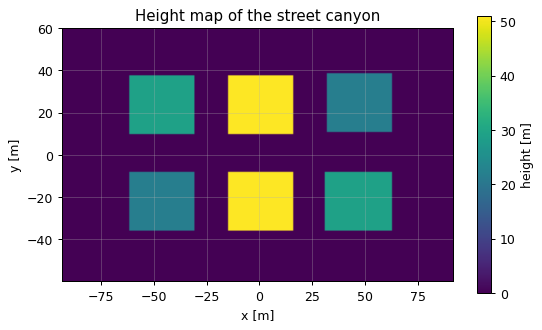

In [10]:
scene = load_scene(sionna.rt.scene.simple_street_canyon, merge_shapes=False)
print(len(scene.objects), "objects; the first ones and their material:")
for name, obj in list(scene.objects.items())[:4]:
    print(f"  {name}: {obj.radio_material.name}")

xs, ys, heights = height_map(scene, pixel=1.0)          # heights[i, j] is the pixel at (xs[j], ys[i])
print("grid of", heights.shape, "pixels; highest building:", round(float(heights.max())), "m")
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(heights, origin="lower", extent=[xs[0], xs[-1], ys[0], ys[-1]])
plt.colorbar(im, ax=ax, label="height [m]")
ax.set(xlabel="x [m]", ylabel="y [m]", title="Height map of the street canyon")
plt.show()

In [11]:
X, Y = np.meshgrid(xs, ys)                           # x and y of every pixel, same shape as heights
inside = distance_to(X, Y, (0.0, 0.0)) <= 60.0       # pixels within 60 m of the point (0, 0)
building = heights > 2.0                             # pixels covered by a building
print(f"open area within 60 m: {100 * np.mean(~building[inside]):.0f} %")

h = heights[inside & building]                       # heights of the building pixels within 60 m
print(f"building heights within 60 m: median {np.median(h):.0f} m, 90th percentile "
      f"{np.percentile(h, 90):.0f} m; higher than 25 m: {100 * np.mean(h > 25):.0f} % of the building area")

open area within 60 m: 62 %
building heights within 60 m: median 29 m, 90th percentile 51 m; higher than 25 m: 70 % of the building area


### 2.2 - Change a scene

A scene is an object: `scene.frequency = 28e9` sets one of its properties (in Hz); `scene.get("tx")`
calls one of its methods and returns the transmitter (TX) named "tx", whose `position` can be set.
`scene.tx_array` and `scene.rx_array` are the antennas of all the transmitters and receivers (RX).
`ITURadioMaterial(name, type, thickness)` creates a material of the International Telecommunication
Union (ITU), given to an object with `obj.radio_material = ...`; its `scattering_coefficient` (0 to 1)
sets the diffuse scattering. In the lab, `load_city` does the first steps and
`building_objects(scene, city)` lists the buildings (all the objects except the ground).

In [12]:
scene = load_scene(sionna.rt.scene.simple_street_canyon, merge_shapes=True)
scene.frequency = 3.5e9                                             # [Hz]
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.add(Transmitter(name="tx", position=[60.0, 0.0, 10.0], power_dbm=30.0))

glass = ITURadioMaterial("all-glass", "glass", thickness=0.1)       # one material for all the buildings
for name, obj in scene.objects.items():
    if name != "floor":                                             # keep the ground as it is
        obj.radio_material = glass
glass.scattering_coefficient = 0.2                                  # rough walls: diffuse scattering
scene.get("tx").position = [60.0, 0.0, 20.0]                        # raise the transmitter
scene.frequency = 28e9
frequency_ghz = float(scene.frequency.numpy()[0]) / 1e9
print(f"{frequency_ghz:g} GHz; TX at {scene.get('tx').position.numpy().ravel()}; materials:",
      sorted({obj.radio_material.name for obj in scene.objects.values()}))

28 GHz; TX at [60.  0. 20.]; materials: ['all-glass', 'concrete']


### 2.3 - Radio maps

`RadioMapSolver()(scene, ...)` computes a radio map on a rectangle (`center`, `size`) made of square
pixels of side `cell_size` (Sionna calls the pixels cells), with `samples_per_tx` rays per transmitter and up to `max_depth` interactions; each mechanism is switched on
or off by its argument (`los`, `specular_reflection`, `diffraction`, ...). `rm.path_gain` (linear) and
`rm.rss` (received power, W) have shape [transmitters, rows (y), columns (x)]; `.numpy()` turns them
into NumPy arrays. With `max_depth=0` only the line-of-sight (LoS) path is computed.
`outdoor_pixels(scene, rm, center, r_min, r_max)` (helper) returns the mask of the outdoor pixels in a
ring around `center`, and the distance of every pixel.

4068 outdoor pixels; P_R >= -80 dBm in 56 % of them; in LoS: 33 %


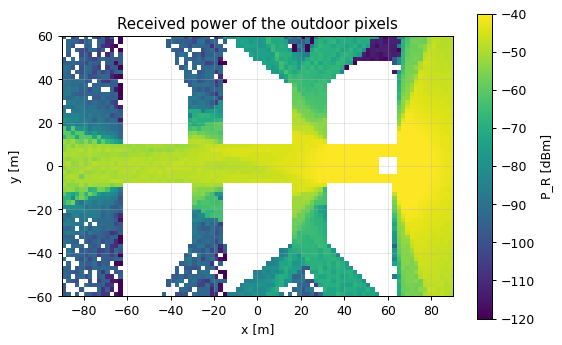

In [13]:
scene = load_scene(sionna.rt.scene.simple_street_canyon, merge_shapes=True)
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = scene.tx_array
scene.add(Transmitter(name="tx", position=[60.0, 0.0, 10.0], power_dbm=30.0))
tx = (60.0, 0.0)

rm = RadioMapSolver()(scene, center=[0.0, 0.0, 1.5], orientation=[0.0, 0.0, 0.0], size=[180.0, 120.0],
                      cell_size=[2.0, 2.0], samples_per_tx=10**6, max_depth=3, los=True,
                      specular_reflection=True, diffuse_reflection=False, diffraction=True,
                      refraction=False, seed=SEED)
rm_los = RadioMapSolver()(scene, center=[0.0, 0.0, 1.5], orientation=[0.0, 0.0, 0.0], size=[180.0, 120.0],
                          cell_size=[2.0, 2.0], samples_per_tx=10**6, max_depth=0, los=True,
                          specular_reflection=False, diffraction=False, refraction=False, seed=SEED)
gain = rm.path_gain.numpy()[0]                   # path gain of every pixel [linear]
prx = watt_to_dbm(rm.rss.numpy()[0])             # received power [dBm]; -inf where no ray arrives
pixels, d = outdoor_pixels(scene, rm, tx, r_min=5.0, r_max=200.0)
print(f"{pixels.sum()} outdoor pixels; P_R >= -80 dBm in {100 * np.mean(prx[pixels] >= -80):.0f} % of them; "
      f"in LoS: {100 * np.mean(rm_los.path_gain.numpy()[0][pixels] > 0):.0f} %")

fig, ax = plt.subplots(figsize=(7, 4.4))
im = ax.imshow(np.where(pixels, prx, np.nan), origin="lower", extent=[-90, 90, -60, 60], vmin=-120, vmax=-40)
plt.colorbar(im, ax=ax, label="P_R [dBm]")
ax.set(xlabel="x [m]", ylabel="y [m]", title="Received power of the outdoor pixels")
plt.show()

### 2.4 - Paths to many receivers and RMS delay spread

`add_random_receivers(scene, center, n, r_min, r_max)` (helper) places receivers at random outdoor
points; `PathSolver()(scene, ...)` computes their paths, with up to `max_depth` interactions and
`samples_per_src` rays. `path_arrays(paths)` (helper) returns arrays [receivers, paths]: the complex
coefficients `a`, the delays `tau` [s] and `valid` (False for the empty slots), and `los`, one value
per receiver. The example computes the path gain (PG) and the RMS delay spread of one receiver;
example 1.6 shows how to repeat a computation for every row.

In [14]:
scene = load_scene(sionna.rt.scene.simple_street_canyon, merge_shapes=True)
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = scene.tx_array
scene.add(Transmitter(name="tx", position=[60.0, 0.0, 10.0], power_dbm=30.0))
points = add_random_receivers(scene, center=(0.0, 0.0), n=20, r_min=0.0, r_max=55.0)

paths = PathSolver()(scene, max_depth=3, los=True, specular_reflection=True, diffraction=True,
                     refraction=False, samples_per_src=10**5, seed=SEED)
a, tau, valid, los = path_arrays(paths)
print("shape of a:", a.shape, "| paths of the first receivers:", valid.sum(axis=1)[:6], "| LoS:", los[:6])

k = 0                                                     # one receiver
p = np.abs(a[k][valid[k]]) ** 2                           # powers of its paths
t = tau[k][valid[k]] - tau[k][valid[k]].min()             # delays after the first path [s]
mean = np.sum(p * t) / p.sum()
tau_rms = np.sqrt(np.sum(p * t ** 2) / p.sum() - mean ** 2)
print(f"receiver {k}: PG {db(p.sum()):.1f} dB, mean delay {1e9 * mean:.1f} ns, "
      f"RMS delay spread {1e9 * tau_rms:.1f} ns")

shape of a: (20, 119) | paths of the first receivers: [20  9 30 55 80 24] | LoS: [False False False False False False]
receiver 0: PG -116.1 dB, mean delay 72.4 ns, RMS delay spread 28.4 ns


### 2.5 - Several transmitters

`set_small_cells(scene, sites)` (helper) replaces the transmitters of a scene with one small cell per
(x, y) site. `rm.rss` then holds one map per transmitter, a stack of maps as in example 1.5:
`prx_all[k]` is the map of transmitter `k`, `prx_all[[0, 2]]` those of a list of transmitters, and the
maximum over axis 0 gives the best server of every pixel. With $\Delta P$ dB more transmit power, $P_R$
grows by $\Delta P$ dB in every pixel.

In [15]:
scene = load_scene(sionna.rt.scene.simple_street_canyon, merge_shapes=True)
scene.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = scene.tx_array
set_small_cells(scene, [(60.0, 0.0), (-60.0, 0.0)])               # tx0 and tx1, 10 m high, 30 dBm

rm = RadioMapSolver()(scene, center=[0.0, 0.0, 1.5], orientation=[0.0, 0.0, 0.0], size=[180.0, 120.0],
                      cell_size=[2.0, 2.0], samples_per_tx=10**6, max_depth=3, los=True,
                      specular_reflection=True, diffuse_reflection=False, diffraction=True,
                      refraction=False, seed=SEED)
prx_all = watt_to_dbm(rm.rss.numpy())                              # [transmitters, rows, columns] [dBm]
pixels, _ = outdoor_pixels(scene, rm, (0.0, 0.0), r_min=0.0, r_max=200.0)
print("shape of prx_all:", prx_all.shape)


def share(prx):                                                    # % of the pixels with P_R >= -80 dBm
    return 100 * np.mean(prx[pixels] >= -80)


print(f"tx0 alone {share(prx_all[0]):.0f} %, with 3 dB more {share(prx_all[0] + 3):.0f} %; "
      f"tx0 and tx1, best server: {share(prx_all[[0, 1]].max(axis=0)):.0f} %")
print("the better transmitter alone:", np.argmax([share(prx_all[k]) for k in range(len(prx_all))]))

shape of prx_all: (2, 60, 90)
tx0 alone 57 %, with 3 dB more 58 %; tx0 and tx1, best server: 80 %
the better transmitter alone: 0
